# 25 · Capability sweeps

Which process makes a simple forecaster struggle? Run the five built-in scenario families, compare errors across independent cases, then vary context length and noise. Construct a hypothesis, plot the result, and explain the model's limitations.

From the repository root, install `python -m pip install -e '.[notebooks]'`, then launch `python -m jupyterlab notebooks`. Use that Python kernel and run all cells in order. See the [notebook guide](README.md). This application is self-contained and runs locally.

In [1]:
from textwrap import fill
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from timegym import Forecast, NaiveForecaster, Pipeline, Scenario
from timegym.diagnostics import evaluate_forecast
from timegym.metrics import mean_reference_mse

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## Fit a straight line through a native factory

Implement `fit(context)` and `predict(future_index)` returning a `Forecast`. The factory creates a fresh model each time. This point-only least-squares model uses consecutive numeric indexes and receives no generator parameters or future outcomes; uncertainty checks remain unsupported.

In [2]:
class LinearTrendForecaster:
    def fit(self, context):
        self.names_ = tuple(context.columns)
        self.origin_ = float(context.index[0])
        times = context.index.to_numpy(dtype=float) - self.origin_
        design = np.column_stack([np.ones(len(times)), times])
        self.coefficients_ = np.linalg.lstsq(design, context.to_numpy(dtype=float), rcond=None)[0]
        return self

    def predict(self, future_index):
        times = future_index.to_numpy(dtype=float) - self.origin_
        design = np.column_stack([np.ones(len(times)), times])
        return Forecast(index=future_index.copy(), point=design @ self.coefficients_,
                        target_names=self.names_)

pipelines = {
    'Last value': Pipeline(NaiveForecaster(strategy='last')),
    'Historical mean': Pipeline(NaiveForecaster(strategy='mean')),
    'Fitted straight line': Pipeline(model_factory=LinearTrendForecaster),
}

## Compare five families

Use fixed-mean Gaussian white noise, linear trend plus white noise, seasonality plus white noise, stationary AR(1), and a random walk with drift. Each has a 12-step horizon and 12 independent cases. Every model sees the same case for a paired comparison. Keep families separate: raw MSE depends on their units and settings.

In [3]:
suite = [
    Scenario('white_noise', context_length=120, horizon=12, parameters={'mean': 2.0, 'sigma': 0.8}),
    Scenario('trend', context_length=120, horizon=12, parameters={'intercept': 1.0, 'slope': 0.08, 'sigma': 0.8}),
    Scenario('seasonal', context_length=120, horizon=12, parameters={'mean': 2.0, 'amplitude': 2.0, 'period': 12.0, 'sigma': 0.8}),
    Scenario('ar1', context_length=120, horizon=12, parameters={'mean': 2.0, 'phi': 0.8, 'sigma': 0.8}),
    Scenario('random_walk', context_length=120, horizon=12, parameters={'intercept': 2.0, 'drift': 0.08, 'sigma': 0.8}),
]
suite_seeds = tuple(range(4100, 4112))
reports = {name: pipeline.test(suite, seeds=suite_seeds) for name, pipeline in pipelines.items()}
assert all(len(report.cases) == len(suite) * len(suite_seeds) for report in reports.values())
display(pd.DataFrame({name: report.summary for name, report in reports.items()}).T)

,cases,diagnostics,status_counts,failed_cases
Last value,60,240,"{'PASS': 60, 'FAIL': 0, 'INCONCLUSIVE': 60, 'U...",0
Historical mean,60,240,"{'PASS': 60, 'FAIL': 0, 'INCONCLUSIVE': 60, 'U...",0
Fitted straight line,60,240,"{'PASS': 60, 'FAIL': 0, 'INCONCLUSIVE': 60, 'U...",0


In [4]:
records = []
for model_name, report in reports.items():
    for result in report.cases:
        records.append({'model': model_name, 'family': result.scenario, 'seed': result.seed,
                        **result.metrics})
suite_scores = pd.DataFrame(records)
assert len(suite_scores) == len(pipelines) * len(suite) * len(suite_seeds)
suite_summary = (suite_scores.groupby(['family', 'model'])
                 .agg(cases=('seed', 'size'),
                      mean_reference_mse=('mean_reference_mse', 'mean'),
                      case_sd=('mean_reference_mse', 'std'),
                      realised_future_mse=('mse', 'mean')))
display(suite_summary.round(4))

cases  mean_reference_mse  case_sd  \
family      model                                                      
ar1         Fitted straight line     12              0.7197   0.6472   
            Historical mean          12              0.1455   0.1456   
            Last value               12              0.5970   0.8485   
random_walk Fitted straight line     12              5.3305   6.2228   
            Historical mean          12             65.6514  64.0739   
            Last value               12              0.3467   0.0000   
seasonal    Fitted straight line     12              2.0323   0.0673   
            Historical mean          12              2.0039   0.0030   
            Last value               12              4.0033   1.4920   
trend       Fitted straight line     12              0.0254   0.0320   
            Historical mean          12             27.8713   0.6777   
            Last value               12              1.2369   0.7928   
white_noise Fitted straight line     12              0.0254   0.0320   
            Historical mean          12              0.0039   0.0030   
            Last value               12              0.7677   0.7800   

                                  realised_future_mse  
family      model                                      
ar1         Fitted straight line               1.9842  
            Historical mean                    1.6376  
            Last value                         2.9583  
random_walk Fitted straight line               7.7045  
            Historical mean                   71.0061  
            Last value                         5.3495  
seasonal    Fitted straight line               2.8548  
            Historical mean                    2.8077  
            Last value                         4.9609  
trend       Fitted straight line               0.6993  
            Historical mean                   29.1897  
            Last value                         2.0138  
white_noise Fitted straight line               0.6993  
            Historical mean                    0.6840  
            Last value                         1.4809

The table separates error against the known conditional mean from error against realized futures. `case_sd` is variation across 12 independent cases, not across their dependent future coordinates. The following panels compare mean-reference errors by family.

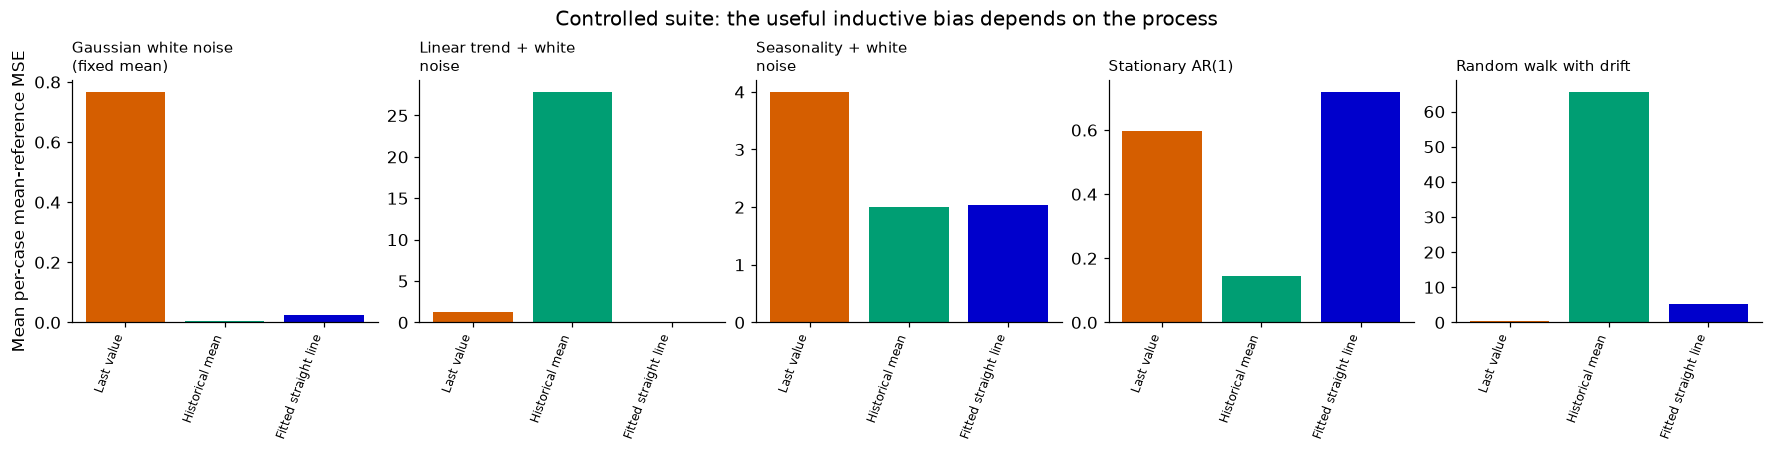

In [5]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4), layout='constrained')
for scenario, ax in zip(suite, axes):
    frame = suite_summary.loc[scenario.kind].reindex(pipelines)
    ax.bar(np.arange(len(frame)), frame['mean_reference_mse'], color=['#D55E00', '#009E73', '#0000CC'])
    ax.set_xticks(np.arange(len(frame)), frame.index, rotation=70, ha='right', fontsize=8)
    ax.set_title(fill(scenario.display_name, width=22), fontsize=10)
    ax.set_ylim(bottom=0)
axes[0].set_ylabel('Mean per-case mean-reference MSE')
fig.suptitle('Controlled suite: the useful inductive bias depends on the process')
plt.show()

Different processes favor different assumptions; these settings do not define a universal leaderboard.

## Distinguish limited capability from a bug

A historical mean cannot extrapolate this linear trend, despite valid output indexes and shapes. Its error is recorded; without a declared capability tolerance, the decision remains inconclusive.

In [6]:
trend_case = suite[1].generate(seed=suite_seeds[0])
weak_forecast = pipelines['Historical mean'].predict(trend_case.task.context, trend_case.task.future_index)
weak_result = evaluate_forecast(trend_case, weak_forecast)
display(pd.DataFrame([{'check': item.name, 'category': item.category, 'status': item.status,
                       'message': item.message} for item in weak_result.diagnostics]))
display(pd.Series(weak_result.metrics).round(4))
assert weak_forecast.validate(trend_case.task) == []

,check,category,status,message
0,forecast_contract,correctness,PASS,"Forecast indices, target order, shapes, finite..."
1,point_accuracy,capability,INCONCLUSIVE,Point scores are descriptive; no capability ac...
2,quantile_accuracy,capability,UNSUPPORTED,No explicit quantile forecasts were supplied.
3,sample_scores,capability,UNSUPPORTED,No joint predictive samples were supplied.


mse                   29.4362
mae                    5.3824
mase                   5.9615
mean_reference_mse    27.2296
dtype: float64

## Inspect the forecast points

The fitted line estimates the trend from context. The gray reference uses the exact generator parameters; even that conditional mean differs from the noisy realized future.

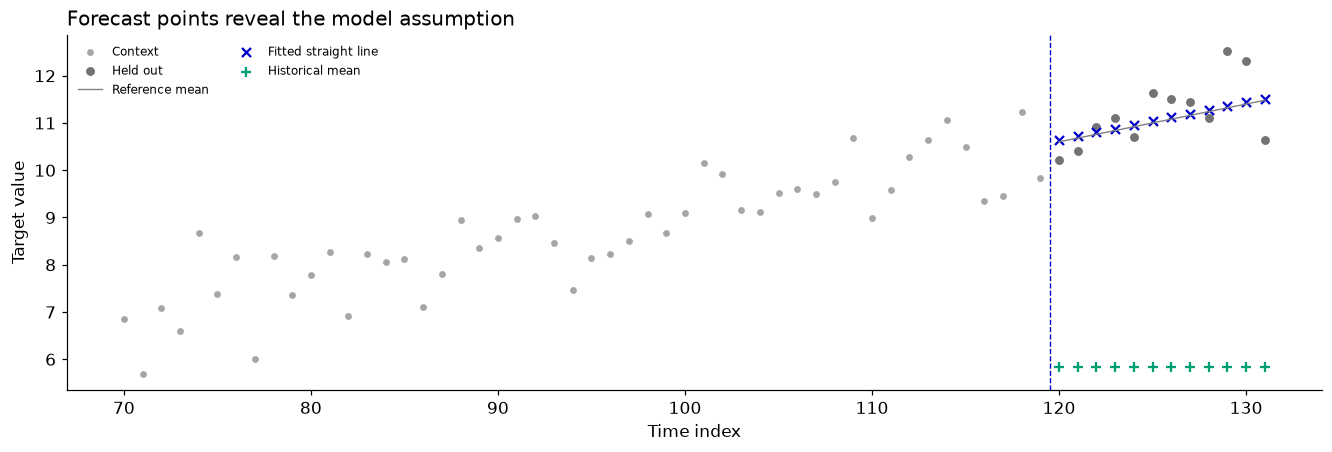

In [7]:
trend_forecast = pipelines['Fitted straight line'].predict(trend_case.task.context, trend_case.task.future_index)
fig, ax = plt.subplots(figsize=(12, 4), layout='constrained')
ax.scatter(trend_case.task.context.index[-50:], trend_case.task.context['y'].iloc[-50:],
           color='0.65', s=12, label='Context')
ax.scatter(trend_case.task.future_index, trend_case.observed['y'], color='0.45', s=23, label='Held out')
ax.plot(trend_case.task.future_index, trend_case.reference.mean[:, 0], color='0.5', linewidth=0.9, label='Reference mean')
ax.scatter(trend_case.task.future_index, trend_forecast.point[:, 0], marker='x',
           color='#0000CC', s=35, label='Fitted straight line')
ax.scatter(trend_case.task.future_index, weak_forecast.point[:, 0], marker='+',
           color='#009E73', s=35, label='Historical mean')
ax.axvline(trend_case.task.future_index[0] - 0.5, color='#0000CC', linestyle='--', linewidth=0.9)
ax.set(xlabel='Time index', ylabel='Target value', title='Forecast points reveal the model assumption')
ax.legend(fontsize=8, ncol=2)
plt.show()

The line model can extrapolate the trend; the historical mean remains tied to the past. Neither contract validity nor one realized score establishes general skill.

## Vary history and noise

Fix slope at 0.08 and horizon at 12. Each setting uses 12 independent seeds, disjoint from the earlier suite and paired across models. Longer history can sharpen the fitted trend but increase the historical mean's structural bias on an upward trend.

In [8]:
context_lengths = (24, 60, 120, 240)
noise_scales = (0.2, 0.8, 1.6)
sweep_seeds = tuple(range(5100, 5112))
sweep_rows = []
for context_length in context_lengths:
    for sigma in noise_scales:
        scenario = Scenario('trend', context_length=context_length, horizon=12,
                            parameters={'intercept': 1.0, 'slope': 0.08, 'sigma': sigma})
        for seed in sweep_seeds:
            current_case = scenario.generate(seed=seed)
            for model_name, pipeline in pipelines.items():
                forecast = pipeline.predict(current_case.task.context, current_case.task.future_index)
                assert forecast.validate(current_case.task) == []
                sweep_rows.append({
                    'context_length': context_length, 'sigma': sigma, 'seed': seed, 'model': model_name,
                    'mean_reference_mse': mean_reference_mse(current_case.reference.mean, forecast.point),
                    'realised_future_mse': np.mean((current_case.observed.to_numpy() - forecast.point) ** 2),
                })
sweep_scores = pd.DataFrame(sweep_rows)
assert len(sweep_scores) == len(context_lengths) * len(noise_scales) * len(sweep_seeds) * len(pipelines)
print(f'{len(sweep_scores)} model evaluations across {len(sweep_scores) // len(pipelines)} generated cases.')

432 model evaluations across 144 generated cases.


In [9]:
sweep_summary = (sweep_scores.groupby(['context_length', 'sigma', 'model'])
                 .agg(cases=('seed', 'size'), mean_error=('mean_reference_mse', 'mean'),
                      case_sd=('mean_reference_mse', 'std'), realised_error=('realised_future_mse', 'mean'))
                 .reset_index())
sweep_summary['monte_carlo_se'] = sweep_summary['case_sd'] / np.sqrt(sweep_summary['cases'])
display(sweep_summary.round(4))

,context_length,sigma,model,cases,mean_error,case_sd,realised_error,monte_carlo_se
0,24,0.2,Fitted straight line,12,0.0101,0.0147,0.0518,0.0042
1,24,0.2,Historical mean,12,2.1529,0.1023,2.2113,0.0295
2,24,0.2,Last value,12,0.4563,0.2080,0.5106,0.0600
3,24,0.8,Fitted straight line,12,0.1617,0.2346,0.8294,0.0677
4,24,0.8,Historical mean,12,2.1762,0.4008,2.9220,0.1157
5,24,0.8,Last value,12,1.1304,1.4065,1.8200,0.4060
6,24,1.6,Fitted straight line,12,0.6469,0.9385,3.3178,0.2709
7,24,1.6,Historical mean,12,2.2401,0.7828,5.0981,0.2260
8,24,1.6,Last value,12,2.8349,4.4060,5.4742,1.2719
9,60,0.2,Fitted straight line,12,0.0022,0.0049,0.0518,0.0014


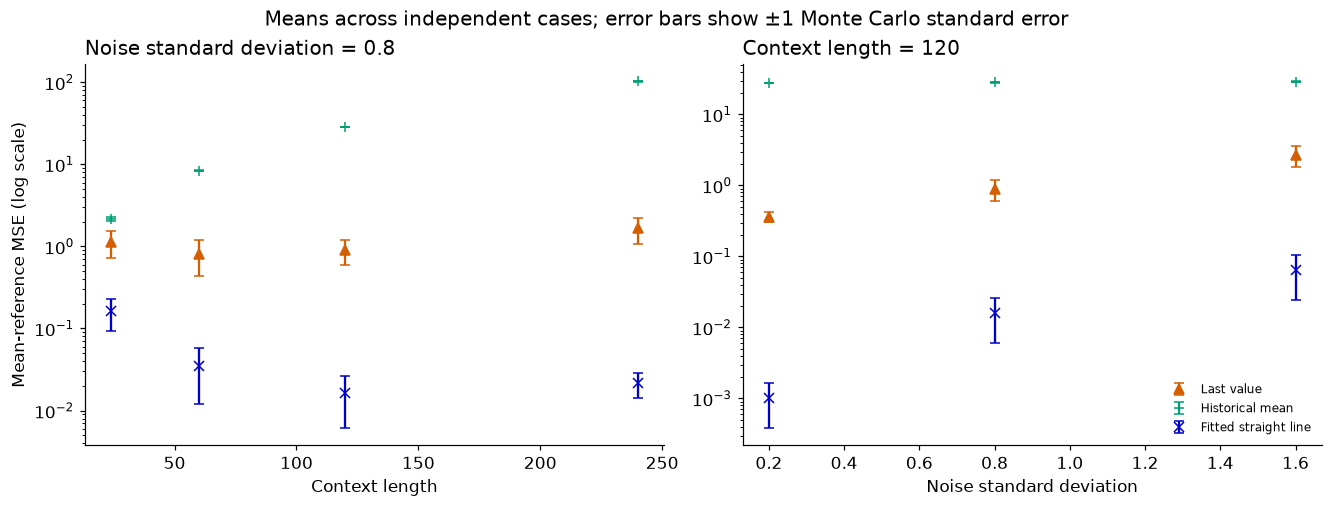

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
model_styles = {'Last value': ('#D55E00', '^'), 'Historical mean': ('#009E73', '+'),
                'Fitted straight line': ('#0000CC', 'x')}
for model_name in pipelines:
    context_curve = sweep_summary[(sweep_summary['model'] == model_name) & (sweep_summary['sigma'] == 0.8)]
    noise_curve = sweep_summary[(sweep_summary['model'] == model_name) & (sweep_summary['context_length'] == 120)]
    for ax, frame, column in [(axes[0], context_curve, 'context_length'), (axes[1], noise_curve, 'sigma')]:
        ax.errorbar(frame[column], frame['mean_error'], yerr=frame['monte_carlo_se'],
                    marker=model_styles[model_name][1], color=model_styles[model_name][0],
                    linestyle='none', capsize=3, label=model_name)
        ax.set_yscale('log')
axes[0].set(xlabel='Context length', ylabel='Mean-reference MSE (log scale)', title='Noise standard deviation = 0.8')
axes[1].set(xlabel='Noise standard deviation', title='Context length = 120')
axes[1].legend(fontsize=8)
fig.suptitle('Means across independent cases; error bars show ±1 Monte Carlo standard error')
plt.show()

Bars show ±1 Monte Carlo standard error of each estimated **average score**. They are not predictive intervals or adjusted hypothesis tests. These 12-case curves need not be monotone; increase replication and freeze a protocol before reporting precise scientific comparisons. The log scale simply makes disparate error magnitudes visible.

## Preserve a reproducible report

Keep scenario manifests, seeds, model settings, dependencies, and source revision with the scores. Built-in models can replay automatically; the custom factory still needs its source notebook and environment. Serialize in memory here.

In [11]:
import json

built_in_report = reports['Last value']
report_payload = json.loads(built_in_report.to_json())
assert len(report_payload['cases']) == len(suite) * len(suite_seeds)
display(pd.Series(report_payload['cases'][0]['manifest']))
display(pd.Series(report_payload['metadata']['pipeline_config']))

repeat = suite[0].generate(seed=suite_seeds[0])
repeat_again = suite[0].generate(seed=suite_seeds[0])
pd.testing.assert_frame_equal(repeat.task.context, repeat_again.task.context)
np.testing.assert_array_equal(repeat.reference.mean, repeat_again.reference.mean)
print('JSON report round-trip and fixed-seed generation checks succeeded.')

array_order                                         horizon_major_C
conditioning      {'future_observations_used': False, 'known_gen...
context_length                                                  120
horizon                                                          12
kind                                                    white_noise
n_targets                                                         1
parameters        {'correlation': [['1.0']], 'mean': ['2.0'], 's...
reference_kind                                 analytic_conditional
schema_version                                                    1
seed                                                           4100
target_names                                                    [y]
dtype: object

model             {'class': 'NaiveForecaster', 'kind': 'builtin'...
replayable                                                     True
schema_version                                                    1
strategy                                                  recursive
window_length                                                    12
dtype: object

JSON report round-trip and fixed-seed generation checks succeeded.


## Ask a sharper next question

Change horizon or process only to test a specific capability. State the target units, relevant settings, replication unit, and any acceptance tolerance before comparing results. Distinguish estimator improvements from pipeline repairs and privileged reference information.

These synthetic results do not establish real-data transfer. Point-error sweeps also say nothing about calibrated predictive uncertainty; use the [univariate](20_univariate_uncertainty.ipynb) and [multivariate](22_multivariate_uncertainty.ipynb) uncertainty applications for that question.